In [3]:
%cd ../src

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
# local modules
import dnn
import cross_validate_dnn as cv_dnn
import scaler_methods

# packages
import numpy as np
import pandas as pd
from itertools import chain
import itertools
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt
import matplotlib as mpl
import math
import random


## Plot settings

In [6]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 15
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = label_size


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']


## Import data

In [161]:
mmd_estimates_exp = np.load("../data_checkpoints/mmd_exp_estimates_v6.npy", allow_pickle = True)
mmd_estimates_sq = np.load("../data_checkpoints/mmd_sq_estimates_v6.npy", allow_pickle = True)
ws2_estimates = np.load("../data_checkpoints/ws2_estimates_v6.npy")

nn_ws2 = np.load('../data_checkpoints/ws2_nncount_v6.npy')
nn_mmd_exp = np.load('../data_checkpoints/mmd_exp_nncount_v6.npy')
nn_mmd_sq = np.load('../data_checkpoints/mmd_sq_nncount_v6.npy')

M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape


## NN Density

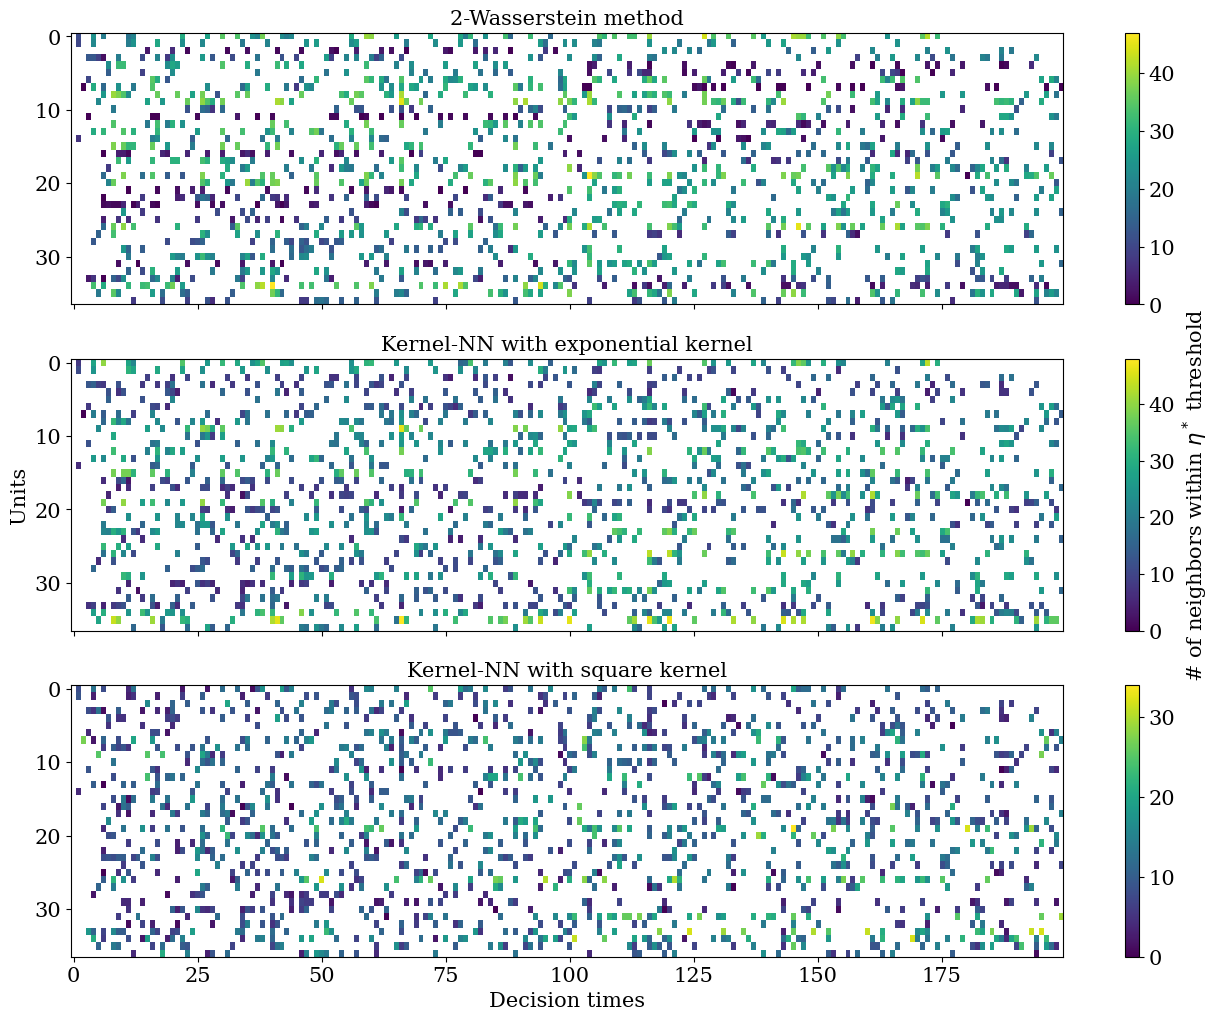

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize=(16, 12), nrows = 3)


pos1 = ax1.imshow(nn_ws2, aspect = 'auto')
pos2 = ax2.imshow(nn_mmd_exp, aspect = 'auto')
pos3 = ax3.imshow(nn_mmd_sq, aspect = 'auto')

fig.colorbar(pos1, ax = ax1)
fig.colorbar(pos2, ax = ax2, label = "# of neighbors within $\eta^*$ threshold")
fig.colorbar(pos3, ax = ax3)

ax3.set_xlabel("Decision times")
ax2.set_ylabel("Units")

ax1.get_xaxis().set_ticklabels([])
ax2.get_xaxis().set_ticklabels([])

ax1.set_title("2-Wasserstein method")
ax2.set_title("Kernel-NN with exponential kernel")
ax3.set_title("Kernel-NN with square kernel")

#fig.suptitle("2-sample Kolmogorov-Smirnov test statistic by DNN method")
plt.savefig("nn_density.pdf", bbox_inches = "tight")

In [ ]:
pd.DataFrame(eta_stars)

,0,1,2,3,4,5
0,27315.647494,14273.827171,0.131236,0.118890,1.486350e+06,1.780220e+06
1,25233.380591,32121.161560,0.069433,0.680192,2.763500e+06,2.981171e+03
2,14034.618539,277.667666,0.069096,0.017171,2.231530e+05,2.643864e+06
3,6722.518848,4845.472739,0.043877,0.022818,1.278810e+06,8.703357e+04
4,224.335496,49537.294494,0.010180,0.022065,2.620052e+05,1.305722e+05
5,1071.874236,30882.142852,0.182946,0.153007,2.024771e+06,1.105770e+06
6,40202.723768,19869.296946,0.198140,0.013633,7.378112e+05,5.104529e+05
7,36.520898,12799.392623,0.098216,0.057871,2.983701e+06,2.409755e+06
8,25942.271339,42313.062922,0.038144,0.074009,2.205073e+06,5.175422e+05
9,23383.902193,49972.994693,0.094910,0.456008,2.358859e+05,2.314807e+06


### Reproduce CDFs using NN density rather than TS-test

(array([220., 126., 140., 137., 231., 247., 163., 163.,  52.,   6.]),
 array([ 0. ,  4.7,  9.4, 14.1, 18.8, 23.5, 28.2, 32.9, 37.6, 42.3, 47. ]),
 <BarContainer object of 10 artists>)

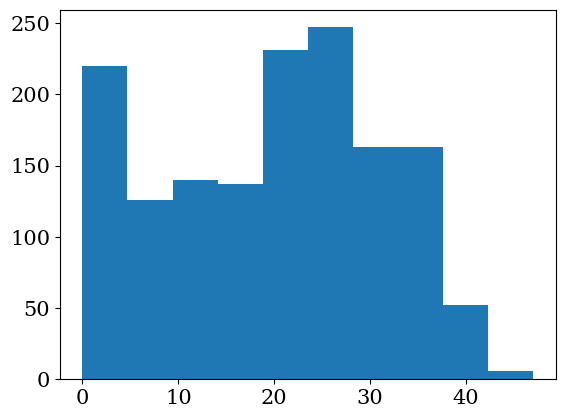

In [16]:
plt.hist(nn_ws2.flatten())

In [120]:
random.seed(a=30)
high_nn_ws2= np.nonzero(nn_ws2[14] >= 20)
rand_num = random.randrange(len(high_nn_ws2[0]))
ws2_i = 14 #high_nn_ws2[0][rand_num]
ws2_j = high_nn_ws2[0][rand_num]


In [124]:
random.seed(a=15)
mid_nn_ws2 = np.nonzero((nn_ws2[14] < 20) & (nn_ws2[14] > 10))
print(len(mid_nn_ws2[0]))
rand_num = random.randrange(len(mid_nn_ws2[0]))
ws2_i_mid = 14 #mid_nn_ws2[0][rand_num]
ws2_j_mid = mid_nn_ws2[0][rand_num]

8


In [125]:
random.seed(a=40)
poor_nn_ws2 = np.nonzero((nn_ws2[14] < 20))
print(len(poor_nn_ws2[0]))
rand_num = random.randrange(len(poor_nn_ws2[0]))
ws2_i_poor = 14 #poor_nn_ws2[0][rand_num]
ws2_j_poor = poor_nn_ws2[0][rand_num]

20


In [65]:
save_ws2_high = ws2_j
save_ws2_mid = ws2_j_mid
save_ws2_poor = ws2_j_poor

# seeds: 365, 10, 200

In [38]:
nn_ws2[33]

array([nan, nan, nan,  3.,  7., nan,  0., nan, 15., 10., 23., nan, nan,
       nan, nan, nan, 16., 22., nan, nan, 21.,  4., nan, nan, 11., nan,
       nan, nan, nan, nan, nan, nan, nan, 19.,  9., nan, nan, nan, nan,
       nan, 22., nan, nan,  6., nan, nan, nan, nan, nan, nan, nan, 18.,
        4., nan, nan, nan, nan, nan, nan, nan, nan, nan, 19., nan, nan,
       nan, 13., nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, 10.,  4., nan, nan, nan, nan, 15., nan, 21., nan,
       nan, 14., 22., nan, nan, nan, nan, nan, 15., 12., nan, nan, nan,
       nan, nan, 11., nan, nan, 14., nan, nan, nan, nan, nan, nan, nan,
       nan,  3., nan, nan, nan, nan, nan, 20., nan, nan, nan, nan, nan,
       nan, 12., nan, nan, nan, 19., nan, nan, nan, nan, nan, nan, nan,
        7., nan, 15., nan, nan, nan, 11., nan, nan, 15., nan, nan, nan,
       nan, nan, nan, nan, 13., nan, nan, 14., nan, nan, nan, nan, nan,
       nan,  9., 12., 10., nan, nan, nan, nan, nan, nan, nan, na

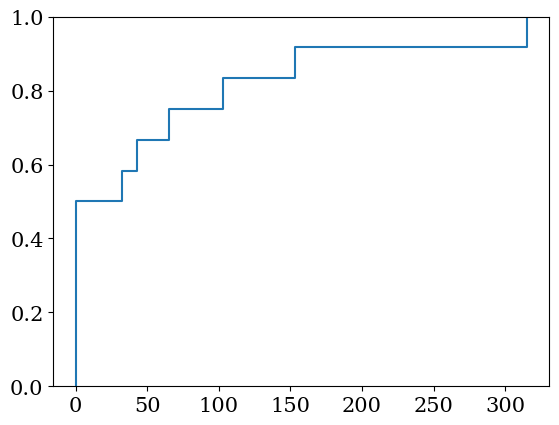

In [121]:
plt.ecdf(M_hs[ws2_i, ws2_j])

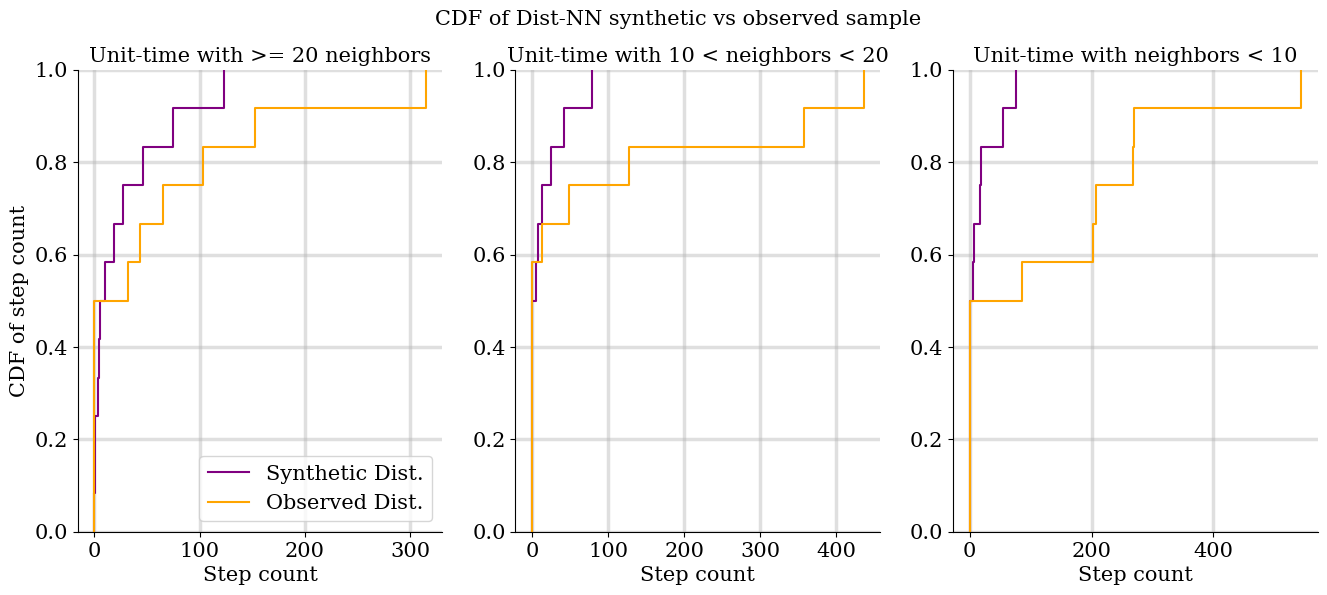

In [126]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (16, 6), ncols = 3)

ax1.ecdf(ws2_estimates[ws2_i, ws2_j].flatten(),color = "purple")
ax1.ecdf(M_hs[ws2_i, ws2_j].flatten(), color="orange")
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("CDF of step count")
ax1.set_title("Unit-time with >= 20 neighbors")

ax2.ecdf(ws2_estimates[ws2_i_mid][ws2_j_mid].flatten(),color = "purple")
ax2.ecdf(M_hs[ws2_i_mid, ws2_j_mid].flatten(), color="orange")
ax2.set_xlabel("Step count")
ax2.set_title("Unit-time with 10 < neighbors < 20")

ax3.ecdf(ws2_estimates[ws2_i_poor][ws2_j_poor].flatten(),color = "purple")
ax3.ecdf(M_hs[ws2_i_poor, ws2_j_poor].flatten(), color="orange")
ax3.set_xlabel("Step count")
ax3.set_title("Unit-time with neighbors < 10")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)

fig.suptitle("CDF of Dist-NN synthetic vs observed sample")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("cdf_ws2_nn.pdf", bbox_inches = "tight")

In [162]:
M_hs[10].shape

(200, 12, 1)

In [171]:
pos_inds = np.nonzero((np.count_nonzero(M_hs.squeeze(axis = -1), axis = 2) > 10), np.nonzero())



2

In [172]:
random.seed(a=265)
high_nn_mmd_exp= np.nonzero((nn_mmd_exp[10] >= 20) & (np.count_nonzero(M_hs[10].squeeze(axis = -1), axis = 1) > 5))
rand_num = random.randrange(len(high_nn_mmd_exp[0]))
print(len(high_nn_mmd_exp[0]))
mmd_exp_i_high = 10 #high_nn_ws2[0][rand_num]
mmd_exp_j_high = high_nn_mmd_exp[0][rand_num]



2


In [180]:
random.seed(a=4)
mid_nn_mmd_exp = np.nonzero((nn_mmd_exp[10] < 20) & (nn_mmd_exp[10] > 5) & (np.count_nonzero(M_hs[10].squeeze(axis = -1), axis = 1) > 5))
print(len(mid_nn_mmd_exp[0]))
rand_num = random.randrange(len(mid_nn_mmd_exp[0]))
mmd_exp_i_mid = 10 #mid_nn_ws2[0][rand_num]
mmd_exp_j_mid = mid_nn_mmd_exp[0][rand_num]

5


In [174]:
random.seed(a=39)
poor_nn_mmd_exp = np.nonzero((nn_mmd_exp[10] < 8))
print(len(poor_nn_mmd_exp[0]))
rand_num = random.randrange(len(poor_nn_mmd_exp[0]))
mmd_exp_i_poor = 10 #poor_nn_ws2[0][rand_num]
mmd_exp_j_poor = poor_nn_mmd_exp[0][rand_num]

4


In [ ]:
save_ws2_high = ws2_j
save_ws2_mid = ws2_j_mid
save_ws2_poor = ws2_j_poor

# seeds: 365, 10, 200

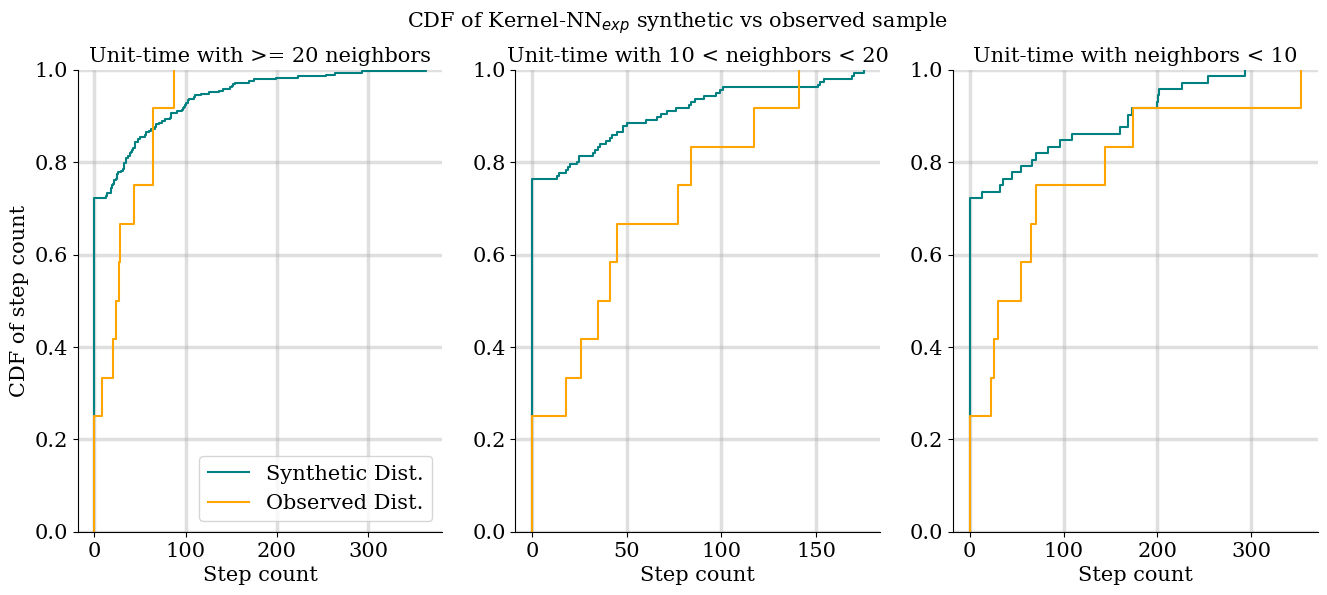

In [182]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (16, 6), ncols = 3)

ax1.ecdf(mmd_estimates_exp[mmd_exp_i_high][mmd_exp_j_high].flatten(),color = "teal")
ax1.ecdf(M_hs[mmd_exp_i_high, mmd_exp_j_high].flatten(), color="orange")
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("CDF of step count")
ax1.set_title("Unit-time with >= 20 neighbors")

ax2.ecdf(mmd_estimates_exp[mmd_exp_i_mid][mmd_exp_j_mid].flatten(),color = "teal")
ax2.ecdf(M_hs[mmd_exp_i_mid, mmd_exp_j_mid].flatten(), color="orange")
ax2.set_xlabel("Step count")
ax2.set_title("Unit-time with 10 < neighbors < 20")

ax3.ecdf(mmd_estimates_exp[mmd_exp_i_poor][mmd_exp_j_poor].flatten(),color = "teal")
ax3.ecdf(M_hs[mmd_exp_i_poor, mmd_exp_j_poor].flatten(), color="orange")
ax3.set_xlabel("Step count")
ax3.set_title("Unit-time with neighbors < 10")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)

fig.suptitle("CDF of Kernel-NN$_{exp}$ synthetic vs observed sample")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("cdf_mmd_exp_nn.pdf", bbox_inches = "tight")

In [192]:
random.seed(a=265)
high_nn_mmd_sq= np.nonzero((nn_mmd_sq[33] >= 20) & (np.count_nonzero(M_hs[33].squeeze(axis = -1), axis = 1) > 5))
rand_num = random.randrange(len(high_nn_mmd_sq[0]))
print(len(high_nn_mmd_sq[0]))
mmd_sq_i_high = 33 #high_nn_ws2[0][rand_num]
mmd_sq_j_high = high_nn_mmd_sq[0][rand_num]



2


In [193]:
random.seed(a=4)
mid_nn_mmd_sq = np.nonzero((nn_mmd_sq[33] < 20) & (nn_mmd_sq[33] > 5) & (np.count_nonzero(M_hs[33].squeeze(axis = -1), axis = 1) > 5))
print(len(mid_nn_mmd_sq[0]))
rand_num = random.randrange(len(mid_nn_mmd_sq[0]))
mmd_sq_i_mid = 33 #mid_nn_ws2[0][rand_num]
mmd_sq_j_mid = mid_nn_mmd_sq[0][rand_num]

1


In [201]:
random.seed(a=10)
poor_nn_mmd_sq = np.nonzero((nn_mmd_exp[33] < 10))
print(len(poor_nn_mmd_sq[0]))
rand_num = random.randrange(len(poor_nn_mmd_sq[0]))
mmd_sq_i_poor = 33 #poor_nn_ws2[0][rand_num]
mmd_sq_j_poor = poor_nn_mmd_sq[0][rand_num]

23


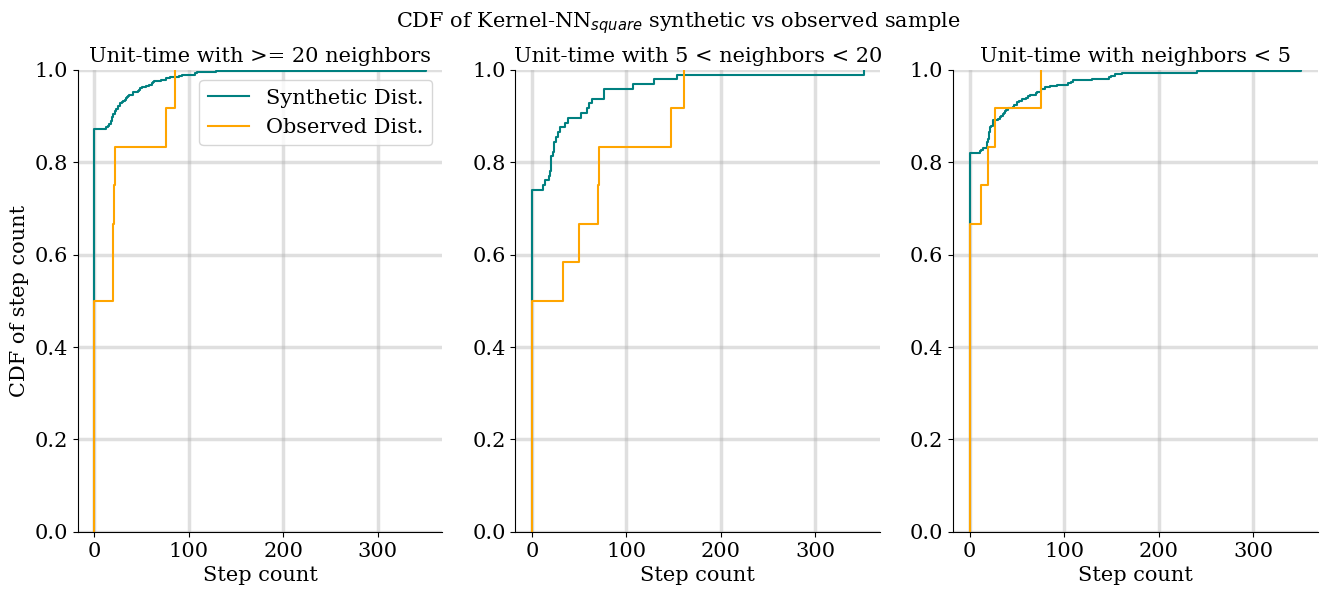

In [202]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (16, 6), ncols = 3)

ax1.ecdf(mmd_estimates_sq[mmd_sq_i_high][mmd_sq_j_high].flatten(),color = "teal")
ax1.ecdf(M_hs[mmd_sq_i_high, mmd_sq_j_high].flatten(), color="orange")
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("CDF of step count")
ax1.set_title("Unit-time with >= 20 neighbors")

ax2.ecdf(mmd_estimates_sq[mmd_sq_i_mid][mmd_sq_j_mid].flatten(),color = "teal")
ax2.ecdf(M_hs[mmd_sq_i_mid, mmd_sq_j_mid].flatten(), color="orange")
ax2.set_xlabel("Step count")
ax2.set_title("Unit-time with 5 < neighbors < 20")

ax3.ecdf(mmd_estimates_sq[mmd_sq_i_poor][mmd_sq_j_poor].flatten(),color = "teal")
ax3.ecdf(M_hs[mmd_sq_i_poor, mmd_sq_j_poor].flatten(), color="orange")
ax3.set_xlabel("Step count")
ax3.set_title("Unit-time with neighbors < 5")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)

fig.suptitle("CDF of Kernel-NN$_{square}$ synthetic vs observed sample")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("cdf_mmd_sq_nn.pdf", bbox_inches = "tight")

## Log-Transform KDE Graphs

In [215]:
import scipy
import seaborn as sns

In [204]:
mmd_estimates_exp = np.load("../data_checkpoints/mmd_exp_estimates_v6.npy", allow_pickle = True)
mmd_estimates_sq = np.load("../data_checkpoints/mmd_sq_estimates_v6.npy", allow_pickle = True)
ws2_estimates = np.load("../data_checkpoints/ws2_estimates_v6.npy")

mmd_estimates_exp_log = np.load("../data_checkpoints/mmd_exp_estimates_v8_log.npy", allow_pickle = True)
mmd_estimates_sq_log = np.load("../data_checkpoints/mmd_sq_estimates_v8_log.npy", allow_pickle = True)
ws2_estimates_log = np.load("../data_checkpoints/ws2_estimates_v8_log.npy")

nn_ws2_log = np.load('../data_checkpoints/ws2_nncount_v8_log.npy')
nn_mmd_exp_log = np.load('../data_checkpoints/mmd_exp_nncount_v8_log.npy')
nn_mmd_sq_log = np.load('../data_checkpoints/mmd_sq_nncount_v8_log.npy')

nn_ws2 = np.load('../data_checkpoints/ws2_nncount_v6.npy')
nn_mmd_exp = np.load('../data_checkpoints/mmd_exp_nncount_v6.npy')
nn_mmd_sq = np.load('../data_checkpoints/mmd_sq_nncount_v6.npy')

M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

M_hs_log = np.log(M_hs + 1)

N, T, n, d = M_hs.shape

First, we graph the KDE of non-log transformed data alongside the their estimates.

In [238]:
np.nonzero(nn_ws2 > 20)[1]

array([  4,  12,  22,  27,  30,  33,  36,  37,  38,  42,  44,  56,  59,
        60,  65,  72,  78,  80,  83,  87,  92, 106, 107, 109, 112, 113,
       116, 127, 129, 132, 137, 139, 145, 146, 147, 148, 151, 154, 155,
       164, 171, 172, 174,   4,  12,  17,  22,  26,  39,  47,  49,  56,
        57,  73,  78,  94,  99, 101, 105, 116, 129, 140, 143, 154, 166,
       119, 121, 124, 152, 161, 172, 176, 187,  17,  20,  26,  51,  55,
        57,  92, 100, 105, 110, 146, 165, 170, 183, 194,   7,   9,  10,
        19,  20,  21,  30,  35,  41,  43,  46,  59,  65,  68,  75,  81,
        85,  87,  20,  55,  68,  98,  16,  17,  49,  59,  60,  62,  66,
        70,  75,  76,  77,  78,  92,  99, 105, 106, 109, 115, 116, 117,
       119, 127, 133, 137, 151, 163, 164, 165, 167, 170, 195, 197, 198,
         4,   9,  16,  27,  35,  39,  47,  48,  62,  64,  66,  68,  69,
        75,  80,  81,  83,  89,  92,  94,  99,   6,   8,   9,  10,  11,
        17,  21,  24,  26,  33,  35,  46,  54,  55,  57,  58,  6

In [280]:
ws2_unit = np.nonzero(nn_ws2_log > 20)[0][0]
ws2_time = np.nonzero(nn_ws2_log > 20)[1][0]
ws2_unit

np.int64(0)

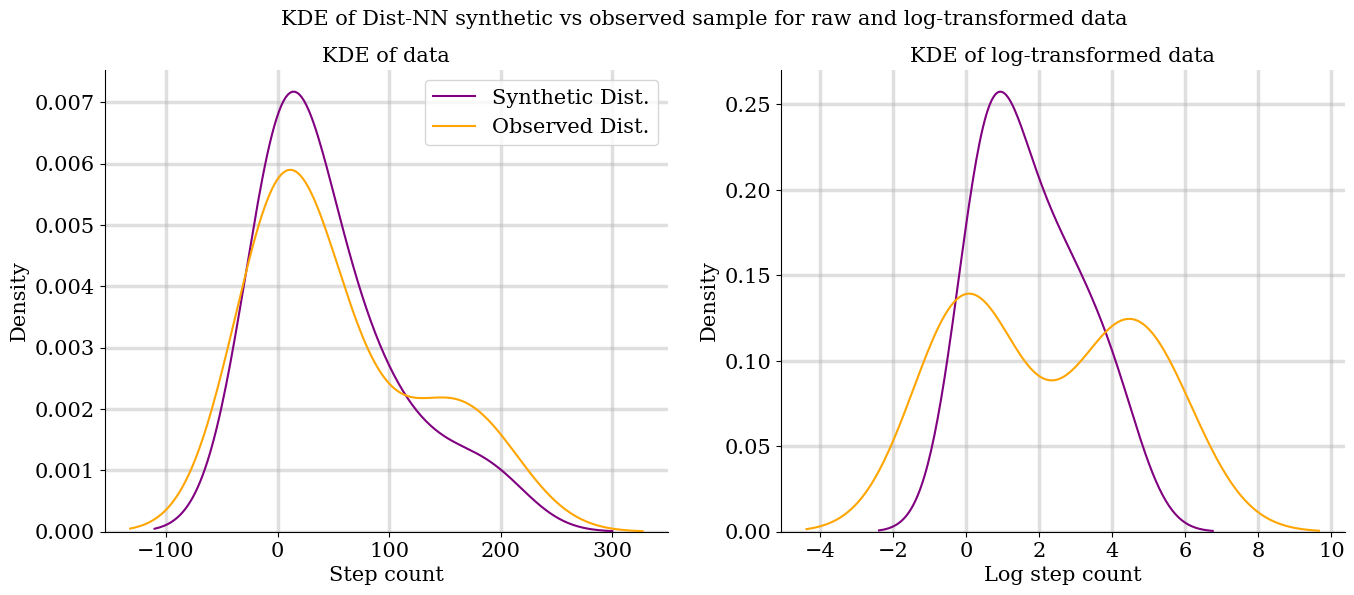

In [282]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2)

sns.kdeplot(ws2_estimates[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax1)
sns.kdeplot(M_hs[ws2_unit, ws2_time].flatten(), color="orange", ax = ax1)
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of data")

sns.kdeplot(ws2_estimates_log[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax2)
sns.kdeplot(M_hs_log[ws2_unit, ws2_time].flatten(), color="orange", ax = ax2)
ax2.set_xlabel("Log step count")
ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


fig.suptitle("KDE of Dist-NN synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("kde_ws2_unit0time4.pdf", bbox_inches = "tight")

In [244]:
mmd_exp_unit = np.nonzero(nn_mmd_exp > 20)[0][0]
mmd_exp_time = np.nonzero(nn_mmd_exp > 20)[1][0]
# 0, 4

np.int64(4)

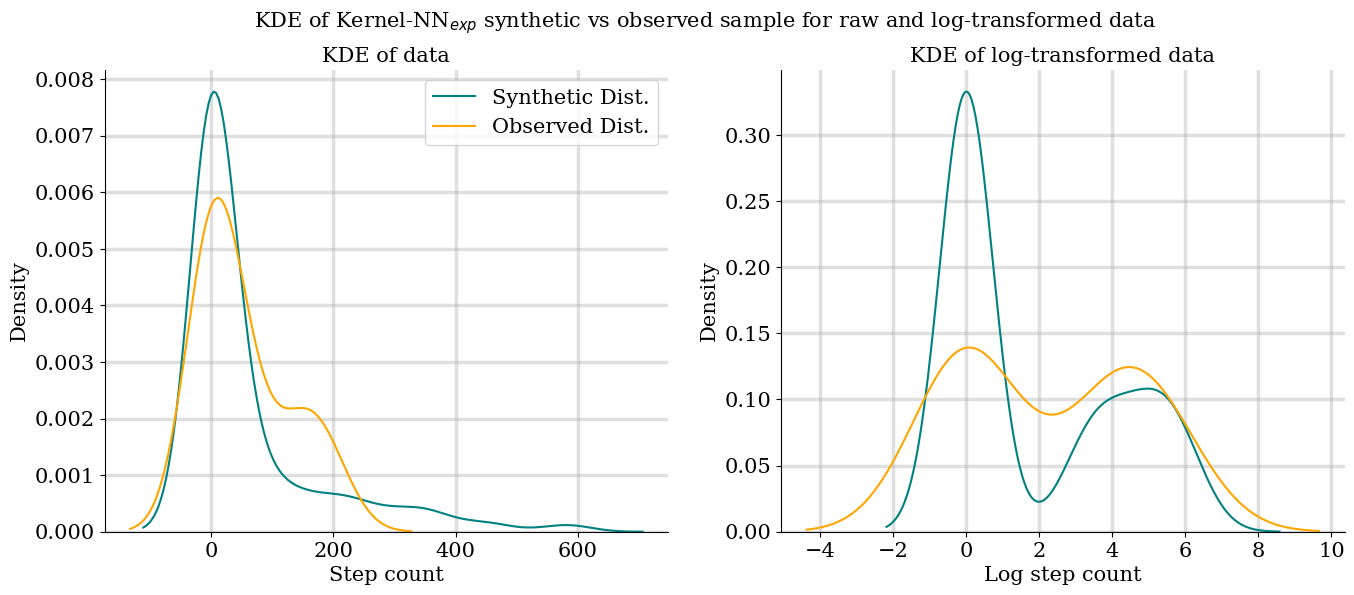

In [283]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2)

sns.kdeplot(mmd_estimates_exp[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax1)
sns.kdeplot(M_hs[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax1)
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of data")

sns.kdeplot(mmd_estimates_exp_log[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax2)
sns.kdeplot(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax2)
ax2.set_xlabel("Log step count")
ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


fig.suptitle("KDE of Kernel-NN$_{exp}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("kde_mmd_exp_unit0time4.pdf", bbox_inches = "tight")

In [249]:
mmd_sq_unit = 0#np.nonzero(nn_mmd_sq > 20)[0][0]
mmd_sq_time = 4 #np.nonzero(nn_mmd_sq > 20)[1][0]

# 0, 72

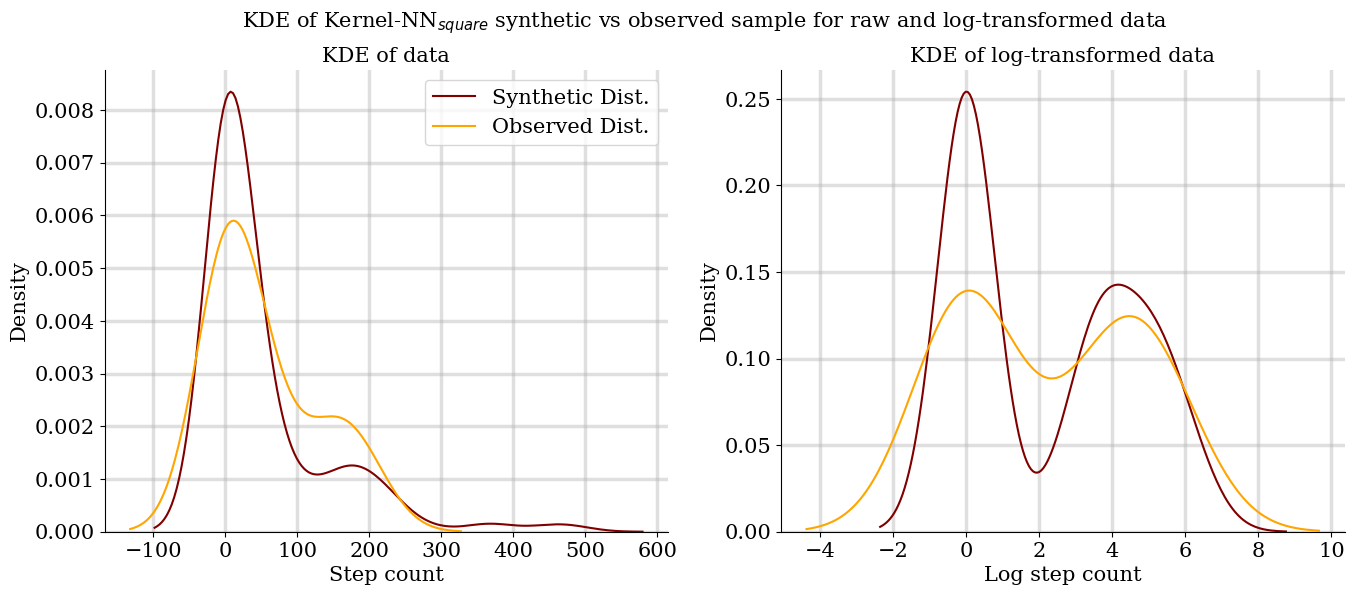

In [284]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2)

sns.kdeplot(mmd_estimates_sq[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax1)
sns.kdeplot(M_hs[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax1)
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of data")

sns.kdeplot(mmd_estimates_sq_log[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax2)
sns.kdeplot(M_hs_log[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax2)
ax2.set_xlabel("Log step count")
ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


fig.suptitle("KDE of Kernel-NN$_{square}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("kde_mmd_sq_unit0time4.pdf", bbox_inches = "tight")